## Introduction

This notebook runs the same synthetic calculations as Chapter 09; no external files are needed except the adjacent Python module.

In [1]:
from pathlib import Path
import json, numpy as np
import chapter09_examples as ex
from pprint import pprint
print('Module:',Path(ex.__file__).name)

Module: chapter09_examples.py


## Gaussian membership

Posterior responsibility of x=2 under equal-prior univariate Gaussians.

In [2]:
posterior=ex._posterior_example()
print('P(k=1|x=2)=',round(float(posterior[0]),6),'P(k=2|x=2)=',round(float(posterior[1]),6))
assert abs(posterior[0]-.817574476)<1e-6

P(k=1|x=2)= 0.817574 P(k=2|x=2)= 0.182426


## EM

Two-component EM for eight deliberately small observations.

In [3]:
toy=np.array([-.7,-.2,.2,.6,2.5,3.2,4.1,4.8])
fit=ex.gmm_em_1d(toy,centers=[0,4],var=1.6)
print('means',fit['means'].round(4),'weights',fit['weights'].round(4))
print('log-likelihood',np.round(fit['loglikelihood'],5))
assert np.all(np.diff(fit['loglikelihood'])>=-1e-8)

means [-0.0255  3.6474] weights [0.4996 0.5004]
log-likelihood [-15.82087 -14.30324 -13.49431 -13.428   -13.42799 -13.42799 -13.42799]


## Fuzzy c-means

Why fuzzy memberships are not GMM probabilities.

In [4]:
u=ex.fuzzy_membership_1d(2,[0,5],m=2)
centers,u2=ex.fuzzy_cmeans_1d([0,.2,.4,3.8,4,4.2],[0,4])
print('u(2):',u.round(6),'new centers:',centers.round(4))
assert np.isclose(u[0],9/13)

u(2): [0.692308 0.307692] new centers: [0.1999 4.0001]


## Dataset

Generate a reproducible overlap dataset, a 20-dimensional dataset, a bicluster and an eight-node graph.

In [5]:
root=Path('.')
x,wide,mat,w=ex.make_data(root)
print('overlap',x.shape,'wide',wide.shape,'matrix',mat.shape,'graph',w.shape)
assert wide.shape[1]==20

overlap (220, 2) wide (220, 20) matrix (10, 9) graph (8, 8)


## High dimensionality

Compare signal and noise features without looking at the hidden synthetic component.

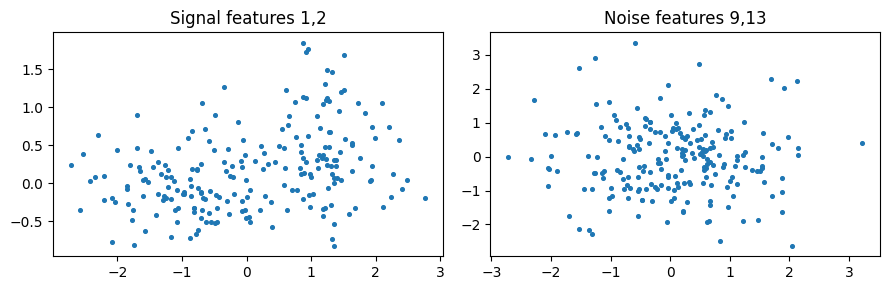

In [6]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(9,3))
axes[0].scatter(wide[:,0],wide[:,1],s=7);axes[0].set_title('Signal features 1,2')
axes[1].scatter(wide[:,8],wide[:,12],s=7);axes[1].set_title('Noise features 9,13')
plt.tight_layout();plt.show()

## Bicluster

The additive row and column effects give zero MSR.

In [7]:
block=mat[2:6,3:8]
print('MSR of intended additive block:',ex.bicluster_msr(block))
assert ex.bicluster_msr(block)<1e-20

MSR of intended additive block: 1.4199496293978213e-30


## Graph Laplacian

Eigenvalues and spectral embedding of the weakly bridged network.

In [8]:
eig,embedding=ex.spectral_embedding(w,2)
print('eigenvalues',eig.round(6));print('embeddings',embedding.round(3))
assert abs(eig[1]-.018953)<1e-5

eigenvalues [-0.        0.018953  1.294872  1.333333  1.333333  1.333333  1.333333
  1.352841]
embeddings [[ 0.702 -0.712]
 [ 0.702 -0.712]
 [ 0.702 -0.712]
 [ 0.723 -0.691]
 [ 0.723  0.691]
 [ 0.702  0.712]
 [ 0.702  0.712]
 [ 0.702  0.712]]


## SNN

Count common neighbors by set intersection.

In [9]:
print('SNN of {2,3,4} and {2,4,5}:',ex.shared_neighbor_similarity([2,3,4],[2,4,5]))
assert ex.shared_neighbor_similarity([2,3,4],[2,4,5])==2

SNN of {2,3,4} and {2,4,5}: 2


## NMF

Nonnegative factors, reconstruction error.

In [10]:
V=np.array([[2,1,0,0],[1,2,0,0],[0,0,1,2],[0,0,2,1],[1,0,1,0]],dtype=float)
W,H,errs=ex.nmf_mu(V,rank=2,steps=300)
print('initial/final NMF error:',round(errs[0],5),round(errs[-1],5))
assert errs[-1]<errs[0]

initial/final NMF error: 3.06228 1.70733


## BIRCH CF

Recover exact centroid and SSE from the compressed statistics.

In [11]:
pts=np.array([[1.,1.],[2.,1.],[5.,4.]])
cf=ex.cf_summary(pts)
print('CF:',cf,'SSE=',ex.cf_sse(cf))
assert np.isclose(ex.cf_sse(cf),44/3)

CF: {'N': 3, 'LS': array([8., 6.]), 'SS': 48.0} SSE= 14.666666666666664


## Reproducibility

Read a deterministic result file and validate selected invariants.

In [12]:
results=ex.demo(root)
print(json.dumps(results,indent=2,ensure_ascii=False))
assert results['synthetic_rows']==220 and results['bicluster_msr']==0

{
  "gmm_means": [
    -0.02549,
    3.64739
  ],
  "gmm_weights": [
    0.49958,
    0.50042
  ],
  "gmm_ll_initial_final": [
    -15.82087,
    -13.42799
  ],
  "posterior_x2": [
    0.817574,
    0.182426
  ],
  "fuzzy_x2_centers_0_5": [
    0.692308,
    0.307692
  ],
  "laplacian_eigenvalues": [
    -0.0,
    0.018953,
    1.294872,
    1.333333,
    1.333333,
    1.333333,
    1.333333,
    1.352841
  ],
  "bicluster_msr": 0.0,
  "cf_n": 3,
  "cf_sse": 14.666667,
  "synthetic_rows": 220,
  "synthetic_features": 20
}
